<a href="https://colab.research.google.com/github/fernandanasc/BookTree/blob/main/notebooks/06_outliers_regras_orcamento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/06_outliers_regras_orcamento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 06 — Cidades com usinas: regras do repasse, cidades parecidas e o orçamento das prefeituras

**Tema:** Para onde vai o dinheiro do Estado nos municípios do RN?

No CP2 vimos que o repasse por habitante **acompanha o PIB e não a pobreza**. O professor pediu para:
1. entender **como o repasse é calculado** (as regras da lei), para explicar o porquê dos resultados;
2. **trabalhar com os outliers**: comparar municípios **do mesmo tamanho e com o mesmo nível de pobreza**,
   em que um recebe muito e o outro pouco, e descobrir **para onde vai esse dinheiro**.

Este notebook também retoma uma pergunta do início do projeto: **quanto as prefeituras dependem dos repasses?**

**Termos usados:**
- **Cidades com usinas:** os 7 municípios que recebem muito mais repasse que os outros (os "outliers" dos notebooks
  03 e 04): Guamaré, São Bento do Norte, Pedra Grande, Parazinho, Galinhos, Bodó e Serra do Mel. Todos têm usinas
  eólicas ou atividade de petróleo e gás.
- **Cidade parecida (sem usina):** para cada cidade com usina, o município mais parecido com ela em tamanho, pobreza e
  região, mas sem indústria forte.

**Ano de referência:** 2023 (último ano com PIB municipal publicado).

**Fontes:**
- `saida/base_municipios_2020_2023.csv` (notebook 01): repasses da SEFAZ/RN, população e CadÚnico.
- `saida/repasses_2004_2025.csv` (notebook 05_a): série longa dos repasses.
- Lei estadual nº 11.253/2022 (critérios do ICMS), Constituição Federal e Lei 7.990/1989.
- IBGE/SIDRA: área territorial (tabela 4714) e valor adicionado por setor (tabela 5938).
- IBGE/Censo 2022: renda domiciliar per capita (tabelas 10295 e 10296; cópia em `dados/ibge`).
- Tesouro Nacional/SICONFI: Declaração de Contas Anuais (DCA) de 2023 de cada prefeitura (receitas e despesas).

## 1. Bibliotecas e estilo dos gráficos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.ticker as mticker
import seaborn as sns
import requests
from scipy.stats import spearmanr

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')

# Paleta do projeto (a mesma dos notebooks 03 e 04)
AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA = '#a3a29b'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, **kwargs):
    """Lê do GitHub do projeto; se não conseguir, lê a cópia local (mesmo caminho)."""
    try:
        return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
    except Exception as erro:
        if os.path.exists(caminho):
            return pd.read_csv(caminho, **kwargs)
        if '404' in str(erro):
            raise FileNotFoundError(
                f'O arquivo "{caminho}" não está no GitHub do projeto. '
                f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
                'e rode a célula de novo.') from None
        raise ConnectionError(
            f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
            'No Kaggle, ligue a opção "Internet" no painel lateral (Settings) e rode de novo. '
            f'Erro original: {erro}') from None

os.makedirs('graficos', exist_ok=True)  # pasta onde os gráficos são salvos (no Colab ela não existe)

## 2. Leitura das bases

In [2]:
base = ler_csv('saida/base_municipios_2020_2023.csv')
d = base[base['ano'] == 2023].copy().reset_index(drop=True)
print(d.shape)

# Os 7 municípios atípicos: os 6 outliers do notebook 04 + Serra do Mel (retirada também no notebook 03).
# Caiçara do Rio do Vento (também retirada no 03) entra na seção 6: em 2023 o repasse dela ainda não tinha subido.
OUTLIERS = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']
CAICARA = 'Caiçara do Rio do Vento'
d['outlier'] = d['municipio'].isin(OUTLIERS)
assert d['outlier'].sum() == 7

(167, 21)


In [3]:
# Área territorial (IBGE, tabela 4714) e valor adicionado por setor (IBGE, tabela 5938). Plano B: cópia em dados/ibge.
def sidra(url):
    r = requests.get(url, timeout=(20, 90))
    r.raise_for_status()
    return pd.DataFrame(r.json()[1:])

try:
    t = sidra('https://apisidra.ibge.gov.br/values/t/4714/n6/in%20n3%2024/v/6318/p/2022')
    area = pd.DataFrame({'cod_ibge': t['D1C'].astype(int), 'area_km2': t['V'].astype(float)})
except Exception as erro:
    print('SIDRA (área) não respondeu, usando a cópia:', type(erro).__name__)
    area = ler_csv('dados/ibge/area_rn.csv')

try:
    t = sidra('https://apisidra.ibge.gov.br/values/t/5938/n6/in%20n3%2024/v/37,498,513,517,6575,525/p/2020,2021')
    vab = pd.DataFrame({'cod_ibge': t['D1C'].astype(int), 'ano': t['D3C'].astype(int), 'variavel': t['D2C'],
                        'valor_mil': pd.to_numeric(t['V'], errors='coerce')})
except Exception as erro:
    print('SIDRA (valor adicionado) não respondeu, usando a cópia:', type(erro).__name__)
    vab = ler_csv('dados/ibge/vab_setor_rn.csv', dtype={'variavel': str})

NOMES_VAB = {'37': 'pib', '498': 'vab_total', '513': 'vab_agro', '517': 'vab_industria', '6575': 'vab_servicos', '525': 'vab_adm_publica'}
vab21 = (vab[vab['ano'] == 2021].pivot_table(index='cod_ibge', columns='variavel', values='valor_mil')
         .rename(columns=NOMES_VAB).reset_index())

censo = ler_csv('dados/ibge/censo2022_renda_rn.csv')[['cod_ibge', 'pct_ate_meio_sm_censo', 'renda_media_pc']]

d = d.merge(area, on='cod_ibge').merge(vab21, on='cod_ibge').merge(censo, on='cod_ibge')
assert len(d) == 167, 'algum município ficou sem área, valor adicionado ou Censo'
d['pct_industria'] = d['vab_industria'] / d['vab_total'] * 100
d['vab_industria_pc'] = d['vab_industria'] * 1000 / d['populacao']

### 2.1 Quem são as cidades com usinas (os "outliers")

São as 7 cidades que **mais recebem repasse por habitante** no RN. Elas foram separadas por dois critérios:
- **6 cidades** (notebook 04): pela regra do boxplot (em escala log), o repasse por habitante fica **acima do limite
  nos 4 anos** de 2020 a 2023;
- **Serra do Mel** (notebook 03): acima do limite em 2 dos 4 anos, e foi retirada também na análise.

A tabela mostra os números que explicam por que elas destoam. A coluna "Atividade principal" vem de fontes externas
(ANEEL e notícias): a base do IBGE só informa que a economia é quase toda **indústria**, não qual indústria.

In [4]:
ATIVIDADE = {
    'Guamaré': 'Petróleo e gás (Petrobras)',
    'São Bento do Norte': 'Parques eólicos',
    'Pedra Grande': 'Parques eólicos',
    'Parazinho': 'Parques eólicos',
    'Galinhos': 'Parques eólicos e salinas',
    'Bodó': 'Parques eólicos',
    'Serra do Mel': 'Parques eólicos',
}

# Critério de seleção: anos (de 4) acima do limite do boxplot em log, como no notebook 04
def acima_do_limite_log(serie):
    valores = np.log(serie)
    q1, q3 = valores.quantile([.25, .75])
    return valores > q3 + 1.5 * (q3 - q1)

anos_acima = (base.assign(acima=base.groupby('ano')['rep_per_capita'].transform(acima_do_limite_log))
              .groupby('municipio')['acima'].sum())

mediana_rep = d['rep_per_capita'].median()
d['posicao_repasse'] = d['rep_per_capita'].rank(ascending=False).astype(int)

lista = (d[d['outlier']].sort_values('rep_per_capita', ascending=False).set_index('municipio'))
tabela_usinas = pd.DataFrame({
    'Atividade principal': lista.index.map(ATIVIDADE),
    'População (2022)': lista['populacao'].map(lambda v: f'{v:,.0f}'.replace(',', '.')),
    'Repasse por habitante (2023)': lista['rep_per_capita'].map(lambda v: f'R$ {v:,.0f}'.replace(',', '.')),
    'Vezes a mediana do RN': lista['rep_per_capita'].div(mediana_rep).map(lambda v: virgula(v, 1) + 'x'),
    'Posição no RN (de 167)': lista['posicao_repasse'].map(lambda v: f'{v}º'),
    'Indústria na economia (2021)': lista['pct_industria'].map(lambda v: virgula(v, 0) + '%'),
    'Pobreza (% até ½ salário mínimo, 2022)': lista['pct_ate_meio_sm_censo'].map(lambda v: virgula(v, 1) + '%'),
    'Anos acima do limite (2020–2023)': lista.index.map(anos_acima).map(lambda v: f'{v} de 4'),
})
tabela_usinas.index.name = 'Cidade'

mediana_ind = d['pct_industria'].median()
mediana_pobreza = d['pct_ate_meio_sm_censo'].median()
fatia_pop = lista['populacao'].sum() / d['populacao'].sum() * 100
fatia_rep = lista['rep_total_real'].sum() / d['rep_total_real'].sum() * 100
print(f'Referência, mediana das 167 cidades do RN: repasse R$ {mediana_rep:,.0f} por habitante | '
      f'indústria {virgula(mediana_ind, 0)}% da economia | pobreza {virgula(mediana_pobreza, 1)}%')
print(f'Juntas, as 7 têm {virgula(fatia_pop)}% da população do RN e recebem {virgula(fatia_rep)}% de todo o repasse (2023).')
print(f'{CAICARA} também tem usinas, mas fica fora da lista: em 2023 ainda era a '
      f'{int(d.loc[d["municipio"] == CAICARA, "posicao_repasse"].iloc[0])}ª do RN (o repasse dela só sobe em 2024; seção 6).')
tabela_usinas

Referência, mediana das 167 cidades do RN: repasse R$ 617 por habitante | indústria 5% da economia | pobreza 54,7%
Juntas, as 7 têm 1,3% da população do RN e recebem 12,6% de todo o repasse (2023).
Caiçara do Rio do Vento também tem usinas, mas fica fora da lista: em 2023 ainda era a 40ª do RN (o repasse dela só sobe em 2024; seção 6).


,Atividade principal,População (2022),Repasse por habitante (2023),Vezes a mediana do RN,Posição no RN (de 167),Indústria na economia (2021),"Pobreza (% até ½ salário mínimo, 2022)",Anos acima do limite (2020–2023)
Cidade,,,,,,,,
Guamaré,Petróleo e gás (Petrobras),15.295,R$ 10.943,"17,7x",1º,75%,"49,9%",4 de 4
São Bento do Norte,Parques eólicos,3.304,R$ 7.850,"12,7x",2º,89%,"53,6%",4 de 4
Pedra Grande,Parques eólicos,3.618,R$ 5.684,"9,2x",3º,78%,"56,3%",4 de 4
Parazinho,Parques eólicos,4.801,R$ 5.572,"9,0x",4º,89%,"61,0%",4 de 4
Galinhos,Parques eólicos e salinas,2.104,R$ 5.178,"8,4x",5º,51%,"35,7%",4 de 4
Bodó,Parques eólicos,2.306,R$ 3.911,"6,3x",6º,87%,"55,5%",4 de 4
Serra do Mel,Parques eólicos,13.091,R$ 3.725,"6,0x",7º,73%,"56,8%",2 de 4


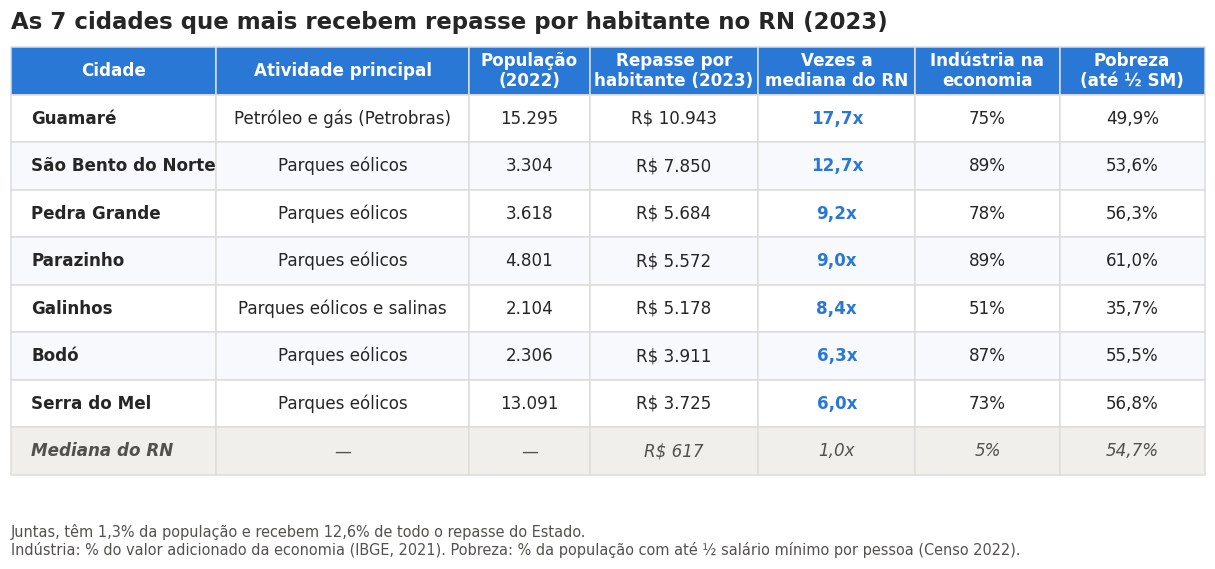

In [5]:
# A mesma tabela em imagem, para usar em slide
linhas = tabela_usinas.reset_index()
colunas = ['Cidade', 'Atividade principal', 'População\n(2022)', 'Repasse por\nhabitante (2023)', 'Vezes a\nmediana do RN',
           'Indústria na\neconomia', 'Pobreza\n(até ½ SM)']
celulas = linhas[['Cidade', 'Atividade principal', 'População (2022)', 'Repasse por habitante (2023)',
                  'Vezes a mediana do RN', 'Indústria na economia (2021)',
                  'Pobreza (% até ½ salário mínimo, 2022)']].values.tolist()
celulas.append(['Mediana do RN', '—', '—', f'R$ {mediana_rep:,.0f}'.replace(',', '.'), '1,0x',
                virgula(mediana_ind, 0) + '%', virgula(mediana_pobreza, 1) + '%'])

fig, ax = plt.subplots(figsize=(14, 5.4))
ax.axis('off')
tab = ax.table(cellText=celulas, colLabels=colunas, cellLoc='center', bbox=[0, 0, 1, 1],
               colWidths=[.17, .21, .1, .14, .13, .12, .12])
tab.auto_set_font_size(False)
tab.set_fontsize(11)
for (lin, col), celula in tab.get_celld().items():
    celula.set_edgecolor('#dddddd')
    if lin == 0:
        celula.set_facecolor(AZUL)
        celula.set_text_props(color='white', fontweight='bold')
    elif lin == len(celulas):
        celula.set_facecolor('#f0efec')
        celula.set_text_props(color=TEXTO_2, fontstyle='italic')
    else:
        celula.set_facecolor('white' if lin % 2 else '#f7f9fc')
    if col == 0 and lin > 0:
        celula.set_text_props(fontweight='bold', ha='left')
        celula._loc = 'left'
    if col == 4 and 0 < lin < len(celulas):
        celula.set_text_props(fontweight='bold', color=AZUL)
ax.set_title('As 7 cidades que mais recebem repasse por habitante no RN (2023)', loc='left', fontsize=15, pad=12)
fig.text(0.125, 0.02, f'Juntas, têm {virgula(fatia_pop)}% da população e recebem {virgula(fatia_rep)}% de todo o repasse do Estado.\n'
         'Indústria: % do valor adicionado da economia (IBGE, 2021). Pobreza: % da população com até ½ salário mínimo '
         'por pessoa (Censo 2022).', fontsize=9.5, color=TEXTO_2, va='bottom')
fig.subplots_adjust(bottom=0.16)
plt.savefig('graficos/00_lista_cidades_com_usinas.png', bbox_inches='tight', dpi=150)
plt.show()

**O que a tabela mostra:**
- Recebem de **6 a 18 vezes** o repasse por habitante da cidade típica do RN, e são as **7 primeiras** do ranking.
- A economia delas é **quase toda indústria** (de 51% a 89%, contra cerca de 5% na cidade típica).
- Mas a **pobreza é parecida com a do resto do estado** (cerca de 55% da população com até ½ salário mínimo).
  Galinhos é a exceção, com menos pobreza.
- Ou seja: **elas recebem muito porque produzem muito, e não porque a população seja mais rica ou mais pobre.**
  O resto do notebook explica esse mecanismo (seções 3 a 5) e para onde vai o dinheiro (seção 7).

## 3. Como o repasse é calculado: as regras da lei

Os 4 repasses que estudamos seguem **duas regras**:

| Repasse | Peso no total (2023) | Regra |
|---|---|---|
| **ICMS** | 85,5% | 25% do ICMS arrecadado pelo Estado vai aos municípios (CF, art. 158, IV), dividido por um **índice de participação** |
| **IPI-Exportação** | 0,2% | 25% da parte do Estado vai aos municípios **pelo mesmo índice do ICMS** (CF, art. 159, § 3º) |
| **Royalties** | 1,7% | 25% dos royalties do Estado vão aos municípios **pelos critérios do ICMS** (Lei 7.990/1989, art. 9º) |
| **IPVA** | 12,6% | 50% do IPVA fica com o município **onde o veículo foi licenciado** (CF, art. 158, III) |

As planilhas da SEFAZ confirmam: ICMS, IPI e royalties usam **a mesma coluna de índice**. Ou seja, **87% do repasse
segue o índice do ICMS**.

**Como o índice do ICMS é formado no RN** (Lei estadual nº 11.253/2022, Anexo Único):

| Critério | 2023 | 2024 em diante |
|---|---|---|
| Valor adicionado (atividade econômica que gera ICMS no município) | **75%** | 70% |
| Distribuição **igual** entre os 167 municípios | **15%** | 10% |
| População | 5% | 5% |
| Área territorial | 5% | 5% |
| Indicadores de educação (creche, alfabetização, EJA) | 0% | 10% |

- O valor adicionado usado é a **média dos 2 anos anteriores** à apuração: por isso o repasse reage à economia
  **com atraso** (caso de Caiçara, seção 6).
- **Nenhum critério mede a pobreza ou a renda da população.** Isso explica o resultado do CP2.

### 3.1 Quanto cada critério rende para cada município
Temos o índice de cada município (fatia do ICMS que ele recebeu) e sabemos a fórmula. Com a população, a área e a
parte igual, calculamos a parte do **valor adicionado** como o que sobra do índice.

In [6]:
d['indice'] = d['rep_icms'] / d['rep_icms'].sum() * 100          # índice efetivo (soma 100%)
d['ind_igual'] = 15 / len(d)
d['ind_populacao'] = 5 * d['populacao'] / d['populacao'].sum()
d['ind_area'] = 5 * d['area_km2'] / d['area_km2'].sum()
d['ind_valor_adicionado'] = d['indice'] - d['ind_igual'] - d['ind_populacao'] - d['ind_area']
assert (d['ind_valor_adicionado'] > 0).all(), 'a parte do valor adicionado não pode ser negativa'
print(f"Soma da parte do valor adicionado: {d['ind_valor_adicionado'].sum():.1f}% (a lei diz 75%)")

# Em reais por habitante: ICMS + IPI + royalties seguem o índice; o IPVA vem à parte
segue_indice = d['rep_icms'] + d['rep_ipi'] + d['rep_royalties']
PARTES = {'ind_valor_adicionado': 'Valor adicionado', 'ind_igual': 'Parte igual', 'ind_area': 'Área',
          'ind_populacao': 'População'}
for coluna, nome in PARTES.items():
    d[nome] = segue_indice * d[coluna] / d['indice'] / d['populacao']
d['IPVA'] = d['rep_ipva'] / d['populacao']
COMPONENTES = ['Valor adicionado', 'Parte igual', 'Área', 'População', 'IPVA']
CORES_COMP = {'Valor adicionado': AZUL, 'Parte igual': VERDE, 'Área': AMARELO, 'População': CINZA, 'IPVA': LARANJA}
assert np.allclose(d[COMPONENTES].sum(axis=1), d['rep_total'] / d['populacao'])

fatias = pd.Series({nome: (d[nome] * d['populacao']).sum() for nome in COMPONENTES}) / d['rep_total'].sum() * 100
print('De cada R$ 100 repassados em 2023:'); print(fatias.round(1).to_string())

Soma da parte do valor adicionado: 75.0% (a lei diz 75%)
De cada R$ 100 repassados em 2023:
Valor adicionado   65.6
Parte igual        13.1
Área                4.4
População           4.4
IPVA               12.5


In [7]:
tipico = d[~d['outlier']][COMPONENTES + ['rep_per_capita']].median().rename('mediana dos demais (R$/hab)')
tipico.to_frame()

,mediana dos demais (R$/hab)
Valor adicionado,100.3
Parte igual,242.7
Área,55.8
População,32.5
IPVA,37.3
rep_per_capita,602.2


**Leitura:**
- No total do dinheiro, o **valor adicionado** manda: cerca de **2/3 de tudo** o que é repassado.
- Mas para o **município típico** a maior parte por habitante vem da **parte igual** (cerca de RS 240/hab),
  e não do valor adicionado (cerca de RS 100/hab). A parte igual é o mesmo valor para todos, então **quanto menor
  a população, mais ela rende por habitante**. Essa é a "cota fixa" que explica por que os municípios muito pequenos
  recebem mais por habitante (a curva em "U" do porte, no CP2).

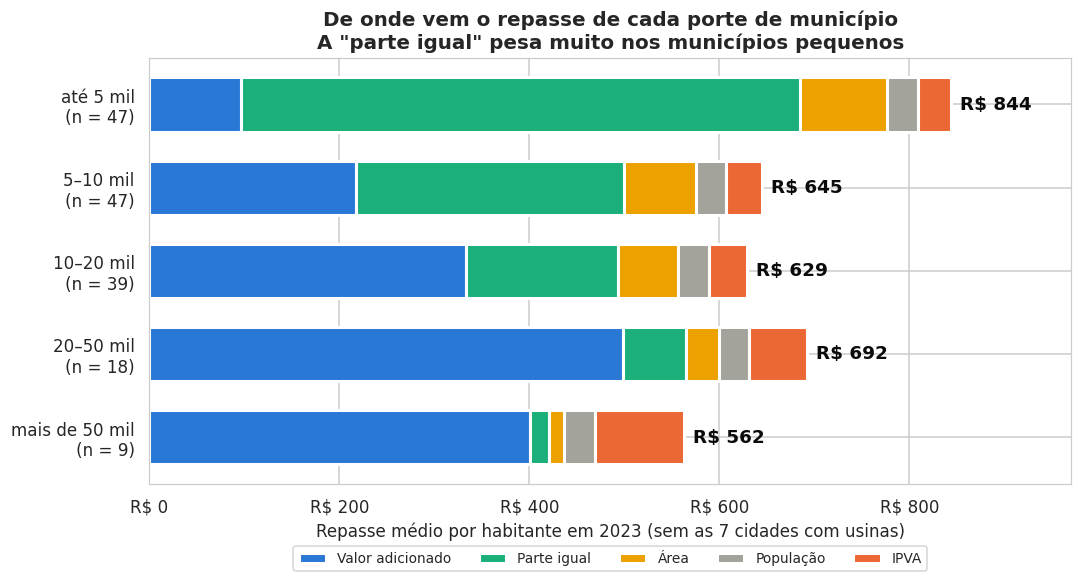

In [8]:
ORDEM_PORTE = ['até 5 mil', '5–10 mil', '10–20 mil', '20–50 mil', 'mais de 50 mil']
por_porte = d[~d['outlier']].groupby('porte')[COMPONENTES].mean().reindex(ORDEM_PORTE)
n_porte = d[~d['outlier']]['porte'].value_counts().reindex(ORDEM_PORTE)

fig, ax = plt.subplots(figsize=(10, 5.5))
esquerda = np.zeros(len(por_porte))
for comp in COMPONENTES:
    ax.barh(range(len(por_porte)), por_porte[comp], left=esquerda, color=CORES_COMP[comp], label=comp,
            edgecolor='white', linewidth=2, height=0.65)
    esquerda += por_porte[comp].values
for i, total in enumerate(esquerda):
    ax.annotate(reais(total), (total, i), xytext=(6, 0), textcoords='offset points', va='center', color=TEXTO,
                fontweight='bold')
ax.set_yticks(range(len(por_porte)), [f'{p}\n(n = {n})' for p, n in zip(ORDEM_PORTE, n_porte)])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, esquerda.max() * 1.15)
ax.set_xlabel('Repasse médio por habitante em 2023 (sem as 7 cidades com usinas)')
ax.set_title('De onde vem o repasse de cada porte de município\nA "parte igual" pesa muito nos municípios pequenos')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.13), fontsize=9)
plt.tight_layout()
plt.savefig('graficos/01_criterios_por_porte.png', bbox_inches='tight')
plt.show()

## 4. Cidades parecidas: mesmo tamanho, mesma pobreza, repasse muito diferente

**Método:** para cada cidade com usina procuramos o município mais parecido em:
- **população** (em log, porque o que importa é a proporção: 3 mil e 3,5 mil são parecidos);
- **pobreza**: % da população com renda de até ½ salário mínimo por pessoa, do **Censo 2022** (mais confiável que o
  CadÚnico, que tem cadastros acima de 100%);
- **mesma mesorregião** (se for de outra, conta como meio desvio-padrão a mais de distância).

Só entram como candidatos municípios **sem grande indústria** (indústria com menos de 20% do valor adicionado),
para que a cidade parecida seja um município "comum".

In [9]:
d['log_pop'] = np.log(d['populacao'])
dp_pop, dp_pobreza = d['log_pop'].std(), d['pct_ate_meio_sm_censo'].std()
candidatos = d[~d['outlier'] & (d['pct_industria'] < 20)]

def gemeo(nome):
    a = d.loc[d['municipio'] == nome].iloc[0]
    dist = (((candidatos['log_pop'] - a['log_pop']) / dp_pop).abs()
            + ((candidatos['pct_ate_meio_sm_censo'] - a['pct_ate_meio_sm_censo']) / dp_pobreza).abs()
            + (candidatos['mesorregiao'] != a['mesorregiao']) * 0.5)
    return candidatos.loc[dist.idxmin(), 'municipio'], dist.min()

PARES = pd.DataFrame([(o, *gemeo(o)) for o in OUTLIERS], columns=['outlier', 'gemeo', 'distancia'])
PARES.rename(columns={'outlier': 'cidade com usina', 'gemeo': 'cidade parecida (sem usina)'})

,cidade com usina,cidade parecida (sem usina),distancia
0,Guamaré,Angicos,0.4
1,São Bento do Norte,Fernando Pedroza,0.3
2,Pedra Grande,Senador Georgino Avelino,0.5
3,Parazinho,Coronel Ezequiel,0.2
4,Galinhos,Santana do Seridó,0.5
5,Bodó,Fernando Pedroza,0.4
6,Serra do Mel,Alexandria,0.3


In [10]:
info = d.set_index('municipio')
COLS_PAR = ['mesorregiao', 'populacao', 'pct_ate_meio_sm_censo', 'renda_media_pc', 'rep_per_capita', 'pct_industria']
linhas = []
for _, p in PARES.iterrows():
    for papel, nome in [('com usina', p['outlier']), ('parecida', p['gemeo'])]:
        linhas.append({'par': p['outlier'], 'papel': papel, 'municipio': nome, **info.loc[nome, COLS_PAR].to_dict()})
tabela_pares = pd.DataFrame(linhas).set_index(['par', 'papel'])
tabela_pares['vezes_a_parecida'] = (tabela_pares['rep_per_capita']
                                 / tabela_pares.xs('parecida', level='papel')['rep_per_capita'].reindex(
                                     tabela_pares.index.get_level_values('par')).values)
tabela_pares

municipio       mesorregiao  \
par                papel                                                   
Guamaré            com usina                   Guamaré  Central Potiguar   
                   parecida                    Angicos  Central Potiguar   
São Bento do Norte com usina        São Bento do Norte  Central Potiguar   
                   parecida           Fernando Pedroza  Central Potiguar   
Pedra Grande       com usina              Pedra Grande    Leste Potiguar   
                   parecida   Senador Georgino Avelino    Leste Potiguar   
Parazinho          com usina                 Parazinho  Agreste Potiguar   
                   parecida           Coronel Ezequiel  Agreste Potiguar   
Galinhos           com usina                  Galinhos  Central Potiguar   
                   parecida          Santana do Seridó  Central Potiguar   
Bodó               com usina                      Bodó  Central Potiguar   
                   parecida           Fernando Pedroza  Central Potiguar   
Serra do Mel       com usina              Serra do Mel    Oeste Potiguar   
                   parecida                 Alexandria    Oeste Potiguar   

                              populacao  pct_ate_meio_sm_censo  \
par                papel                                         
Guamaré            com usina      15295                   49.9   
                   parecida       11632                   49.2   
São Bento do Norte com usina       3304                   53.6   
                   parecida        2938                   54.7   
Pedra Grande       com usina       3618                   56.3   
                   parecida        4065                   59.5   
Parazinho          com usina       4801                   61.0   
                   parecida        5117                   61.8   
Galinhos           com usina       2104                   35.7   
                   parecida        2696                   37.5   
Bodó               com usina       2306                   55.5   
                   parecida        2938                   54.7   
Serra do Mel       com usina      13091                   56.8   
                   parecida       13640                   58.9   

                              renda_media_pc  rep_per_capita  pct_industria  \
par                papel                                                      
Guamaré            com usina           841.0        10,943.0           75.0   
                   parecida            913.6           503.5            4.2   
São Bento do Norte com usina           775.9         7,849.7           88.7   
                   parecida            821.0         1,018.7            4.7   
Pedra Grande       com usina           865.0         5,684.2           78.1   
                   parecida            676.6           594.3            1.6   
Parazinho          com usina           692.9         5,572.2           88.7   
                   parecida            623.8           542.4            3.2   
Galinhos           com usina           993.7         5,177.6           51.3   
                   parecida          1,041.0         1,001.9            9.5   
Bodó               com usina           748.5         3,910.9           86.7   
                   parecida            821.0         1,018.7            4.7   
Serra do Mel       com usina           697.8         3,724.7           73.2   
                   parecida            767.8           377.5            2.2   

                              vezes_a_parecida  
par                papel                        
Guamaré            com usina              21.7  
                   parecida                1.0  
São Bento do Norte com usina               7.7  
                   parecida                1.0  
Pedra Grande       com usina               9.6  
                   parecida                1.0  
Parazinho          com usina              10.3  
                   parecida                1.0  
Galinhos        

**Leitura:** em todos os pares, população e pobreza são quase iguais, mas a cidade com usina recebe de **4 a 22 vezes** mais
por habitante. A coluna que muda é a **% da indústria** no valor adicionado: de 51% a 89% nas cidades com usinas,
contra menos de 10% nas parecidas.

### 4.1 De onde vem a diferença
Decompondo o repasse de cada par pelos critérios da lei:

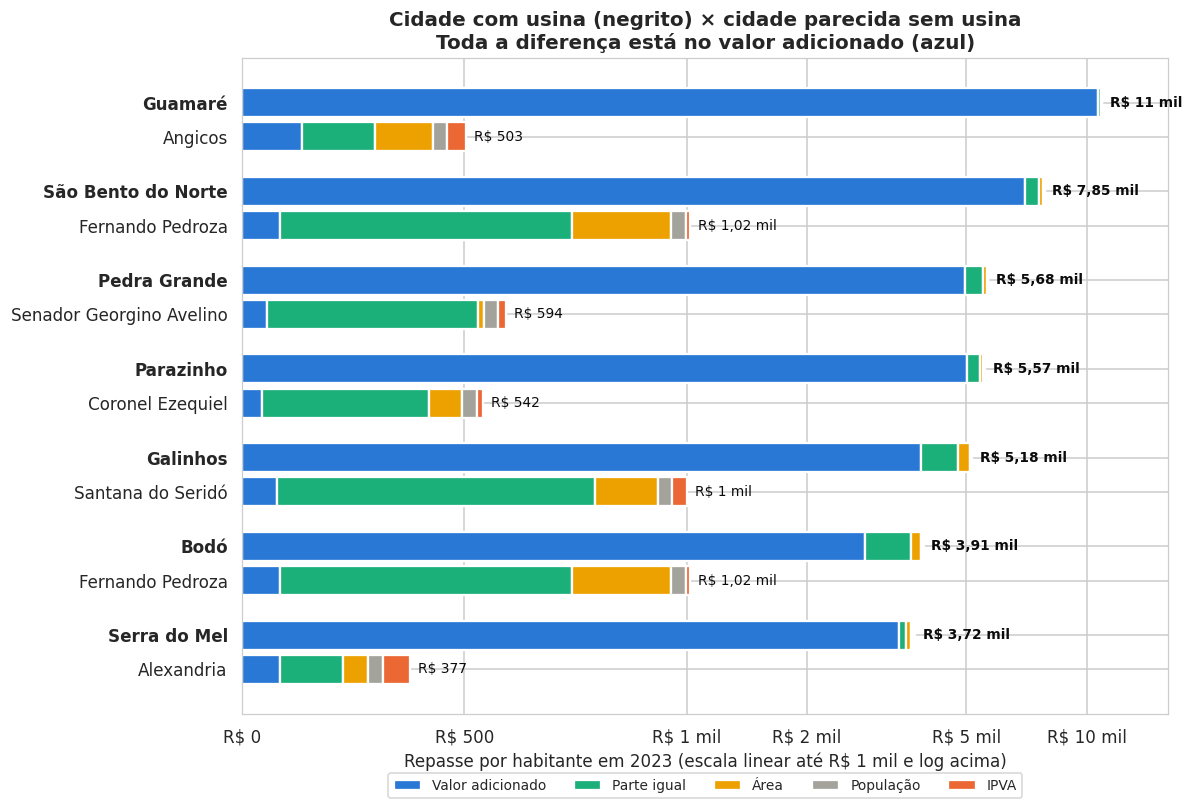

In [11]:
fig, ax = plt.subplots(figsize=(11, 7.5))
y, rotulos = [], []
for i, p in PARES.iterrows():
    for j, nome in enumerate([p['outlier'], p['gemeo']]):
        pos = i * 2.6 + j
        y.append(pos); rotulos.append(nome)
        esquerda = 0
        for comp in COMPONENTES:
            v = info.loc[nome, comp]
            ax.barh(pos, v, left=esquerda, color=CORES_COMP[comp], edgecolor='white', linewidth=1.5, height=0.85,
                    label=comp if (i == 0 and j == 0) else None)
            esquerda += v
        ax.annotate(reais(esquerda), (esquerda, pos), xytext=(5, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXTO, fontweight='bold' if j == 0 else 'normal')
ax.set_yticks(y, rotulos)
for rot in ax.get_yticklabels():
    if rot.get_text() in OUTLIERS:
        rot.set_fontweight('bold')
ax.invert_yaxis()
ax.set_xscale('symlog', linthresh=1000)
ax.xaxis.set_major_locator(mticker.FixedLocator([0, 500, 1000, 2000, 5000, 10000]))
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, 16000)
ax.set_xlabel('Repasse por habitante em 2023 (escala linear até R$ 1 mil e log acima)')
ax.set_title('Cidade com usina (negrito) × cidade parecida sem usina\nToda a diferença está no valor adicionado (azul)')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=9)
plt.tight_layout()
plt.savefig('graficos/02_pares_decomposicao.png', bbox_inches='tight')
plt.show()

In [12]:
dif = pd.DataFrame({p['outlier']: info.loc[p['outlier'], COMPONENTES] - info.loc[p['gemeo'], COMPONENTES]
                    for _, p in PARES.iterrows()}).T.astype(float)
dif['total'] = dif.sum(axis=1)
print('Diferença por habitante (cidade com usina − cidade parecida), em R$:')
dif.round(0)

Diferença por habitante (cidade com usina − cidade parecida), em R$:


,Valor adicionado,Parte igual,Área,População,IPVA,total
Guamaré,"10,576.0",-40.0,-95.0,-0.0,-1.0,"10,439.0"
São Bento do Norte,"6,946.0",-73.0,-46.0,0.0,3.0,"6,831.0"
Pedra Grande,"4,910.0",59.0,111.0,0.0,10.0,"5,090.0"
Parazinho,"4,973.0",25.0,24.0,0.0,8.0,"5,030.0"
Galinhos,"3,783.0",201.0,187.0,0.0,4.0,"4,176.0"
Bodó,"2,710.0",180.0,0.0,-0.0,2.0,"2,892.0"
Serra do Mel,"3,312.0",6.0,39.0,0.0,-10.0,"3,347.0"


In [13]:
print('Fatia da diferença explicada pelo valor adicionado:',
      f"{virgula(dif['Valor adicionado'].sum() / dif['total'].sum() * 100)}%")

Fatia da diferença explicada pelo valor adicionado: 98,4%


## 5. De onde vem esse valor adicionado: indústria

O valor adicionado da lei do ICMS conta as operações que geram ICMS. A geração de **energia** (parques eólicos) e a
**extração e processamento de petróleo e gás** entram como **indústria** no PIB do IBGE. Comparamos a parte do
repasse que vem do valor adicionado com o valor adicionado da indústria por habitante (IBGE, 2021, um dos dois anos
usados no índice de 2023).

Spearman entre a parte "valor adicionado" do repasse e a indústria por habitante: 0.78


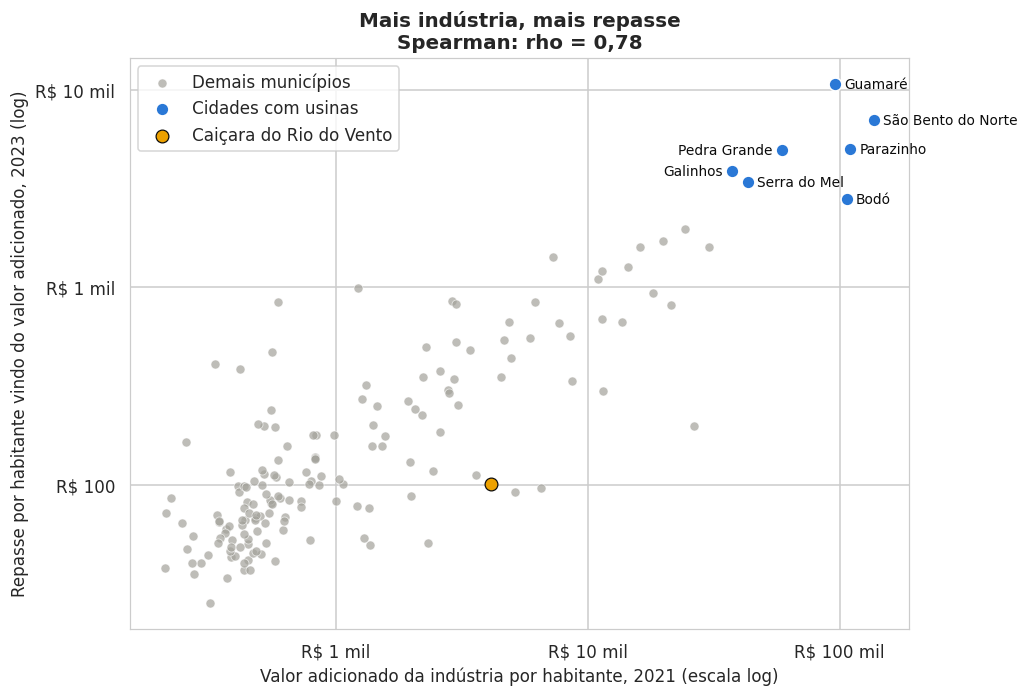

In [14]:
rho = spearmanr(d['Valor adicionado'], d['vab_industria_pc'])[0]
print(f'Spearman entre a parte "valor adicionado" do repasse e a indústria por habitante: {rho:.2f}')

fig, ax = plt.subplots(figsize=(9.5, 6.5))
demais = d[~d['outlier']]
ax.scatter(demais['vab_industria_pc'], demais['Valor adicionado'], s=35, color=CINZA, alpha=0.7,
           edgecolor='white', linewidth=0.5, label='Demais municípios')
out = d[d['outlier']]
ax.scatter(out['vab_industria_pc'], out['Valor adicionado'], s=70, color=AZUL, edgecolor='white', linewidth=1,
           label='Cidades com usinas', zorder=3)
for _, linha in out.iterrows():
    esquerda = linha['municipio'] in ['Pedra Grande', 'Galinhos']
    ax.annotate(linha['municipio'], (linha['vab_industria_pc'], linha['Valor adicionado']),
                xytext=(-6, -3) if esquerda else (6, -3), ha='right' if esquerda else 'left',
                textcoords='offset points', fontsize=9, color=TEXTO)
cai = d[d['municipio'] == CAICARA].iloc[0]
ax.scatter(cai['vab_industria_pc'], cai['Valor adicionado'], s=70, color=AMARELO, edgecolor=TEXTO, linewidth=0.8,
           label='Caiçara do Rio do Vento', zorder=3)
ax.set_xscale('log'); ax.set_yscale('log')
ax.xaxis.set_major_formatter(FORMATO_REAIS); ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlabel('Valor adicionado da indústria por habitante, 2021 (escala log)')
ax.set_ylabel('Repasse por habitante vindo do valor adicionado, 2023 (log)')
ax.set_title(f'Mais indústria, mais repasse\nSpearman: rho = {virgula(rho, 2)}')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('graficos/03_industria_x_valor_adicionado.png', bbox_inches='tight')
plt.show()

**Leitura:** a relação é forte (rho ≈ 0,78). As cidades com usinas estão no canto de cima à direita: muita indústria por
habitante e, por isso, muito repasse. **Caiçara do Rio do Vento** (amarelo) tem indústria alta, mas repasse ainda
baixo em 2023: é o atraso de 2 anos da regra (ver a seção 6).

**Cuidado:** o IBGE não separa "energia eólica" de outras indústrias na base municipal. A ligação com os parques
eólicos e com o petróleo vem do conhecimento sobre esses municípios e é uma **hipótese bem fundamentada**, não uma
medição direta.

## 6. Quando cada cidade com usina "decolou"
A fatia de cada município no ICMS de 2004 a 2025 mostra o momento em que a atividade industrial chegou.

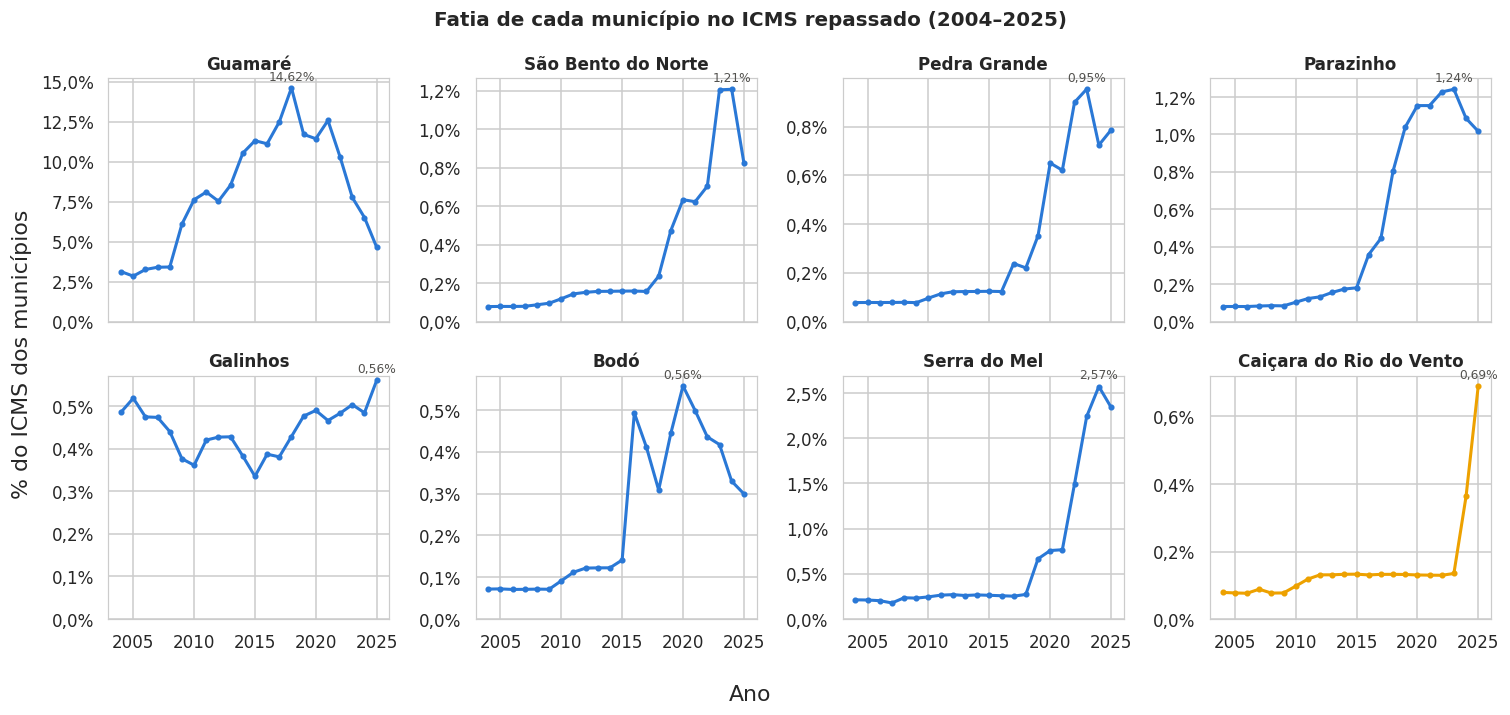

In [15]:
longa = ler_csv('saida/repasses_2004_2025.csv')
icms = longa[longa['tipo'] == 'ICMS'].copy()
icms['indice'] = icms['valor'] / icms.groupby('ano')['valor'].transform('sum') * 100
serie = icms.pivot_table(index='ano', columns='municipio', values='indice')

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharex=True)
for ax, nome in zip(axes.flat, OUTLIERS + [CAICARA]):
    cor = AMARELO if nome == CAICARA else AZUL
    ax.plot(serie.index, serie[nome], color=cor, marker='o', markersize=3, linewidth=2)
    ax.set_title(nome, fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: virgula(v, 1) + '%'))
    ax.set_ylim(0, None)
    pico = serie[nome].idxmax()
    ax.annotate(virgula(serie.loc[pico, nome], 2) + '%', (pico, serie.loc[pico, nome]), xytext=(0, 5),
                textcoords='offset points', ha='center', fontsize=8, color=TEXTO_2)
fig.suptitle('Fatia de cada município no ICMS repassado (2004–2025)', fontweight='bold', fontsize=13)
fig.supxlabel('Ano'); fig.supylabel('% do ICMS dos municípios')
plt.tight_layout()
plt.savefig('graficos/04_linha_do_tempo_outliers.png', bbox_inches='tight')
plt.show()

In [16]:
serie[OUTLIERS + [CAICARA]].loc[[2004, 2010, 2015, 2018, 2020, 2023, 2025]].T.round(2)

ano,2004,2010,2015,2018,2020,2023,2025
municipio,,,,,,,
Guamaré,3.1,7.6,11.3,14.6,11.4,7.8,4.7
São Bento do Norte,0.1,0.1,0.2,0.2,0.6,1.2,0.8
Pedra Grande,0.1,0.1,0.1,0.2,0.7,0.9,0.8
Parazinho,0.1,0.1,0.2,0.8,1.1,1.2,1.0
Galinhos,0.5,0.4,0.3,0.4,0.5,0.5,0.6
Bodó,0.1,0.1,0.1,0.3,0.6,0.4,0.3
Serra do Mel,0.2,0.2,0.3,0.3,0.8,2.2,2.3
Caiçara do Rio do Vento,0.1,0.1,0.1,0.1,0.1,0.1,0.7


**Leitura:**
- Os municípios pequenos ficam no **piso de cerca de 0,1%** (praticamente só a parte igual) até receberem
  indústria. Aí a fatia salta: **Bodó** em 2016, **Parazinho** de 2016 a 2019, **Pedra Grande** de 2017 a 2020,
  **São Bento do Norte** de 2018 a 2023, **Serra do Mel** de 2019 a 2023, **Caiçara** em 2024–2025.
- **Galinhos** já tinha fatia alta desde 2004 e ficou perto de 0,5% em todo o período.
- **Guamaré** é diferente: já era alta em 2004, subiu até 14,6% em 2018 e caiu para 4,7% em 2025. A queda coincide
  com a saída da Petrobras dos campos terrestres do RN (hipótese a confirmar).
- **O ICMS é um bolo fixo (25%)**: quando um município ganha fatia, todos os outros perdem um pouco. A queda de
  Guamaré, por exemplo, liberou cerca de 10 pontos percentuais para os demais.

## 7. Para onde vai o dinheiro: o orçamento das prefeituras (SICONFI 2023)

Cada prefeitura declara ao Tesouro Nacional quanto arrecadou e gastou, por área (a **função** de governo:
educação, saúde, administração etc.). Usamos a Declaração de Contas Anuais (DCA) de 2023:
- **Anexo I-C**: receitas (impostos próprios, transferências da União, do Estado, FUNDEB);
- **Anexo I-E**: despesas empenhadas por função.

A API do SICONFI precisa de uma consulta por município. Para o notebook rodar rápido, lemos a cópia salva em
`dados/siconfi/dca_2023_rn.csv`. Para baixar de novo, mude `BAIXAR_SICONFI` para `True`.

In [17]:
BAIXAR_SICONFI = False

def baixar_dca(cod_ibge, anexo):
    r = requests.get('https://apidatalake.tesouro.gov.br/ords/siconfi/tt/dca',
                     params={'an_exercicio': 2023, 'no_anexo': anexo, 'id_ente': cod_ibge}, timeout=60)
    r.raise_for_status()
    return r.json()['items']

if BAIXAR_SICONFI:
    itens = [i for cod in d['cod_ibge'] for anexo in ['DCA-Anexo I-C', 'DCA-Anexo I-E'] for i in baixar_dca(cod, anexo)]
    dca = pd.DataFrame(itens)
else:
    dca = ler_csv('dados/siconfi/dca_2023_rn.csv')
print(dca.shape, '| prefeituras:', dca['cod_ibge'].nunique())
print('Sem DCA em 2023:', d.loc[~d['cod_ibge'].isin(dca['cod_ibge']), 'municipio'].tolist())

(4973, 8) | prefeituras: 166
Sem DCA em 2023: ['Porto do Mangue']


In [18]:
receitas = dca[(dca['anexo'] == 'DCA-Anexo I-C') & (dca['coluna'] == 'Receitas Brutas Realizadas')]
CONTAS = {'RO1.0.0.0.00.0.0': 'receita_corrente', 'RO1.1.1.0.00.0.0': 'impostos_proprios',
          'RO1.7.0.0.00.0.0': 'transferencias', 'RO1.7.1.1.51.0.0': 'fpm', 'RO1.7.2.0.00.0.0': 'transf_estado',
          'RO1.7.5.0.00.0.0': 'fundeb_recebido'}
rec = receitas[receitas['cod_conta'].isin(CONTAS)].pivot_table(index='cod_ibge', columns='cod_conta', values='valor')
rec = rec.rename(columns=CONTAS)
rec['fundeb_deduzido'] = (dca[(dca['coluna'] == 'Deduções - FUNDEB') & (dca['cod_conta'] == 'ReceitasExcetoIntraOrcamentarias')]
                          .set_index('cod_ibge')['valor'])

FUNCOES = {'Despesas Exceto Intraorçamentárias': 'Total', '12 - Educação': 'Educação', '10 - Saúde': 'Saúde',
           '04 - Administração': 'Administração', '15 - Urbanismo': 'Urbanismo', '01 - Legislativa': 'Legislativo (Câmara)',
           '08 - Assistência Social': 'Assistência social'}
desp = (dca[(dca['anexo'] == 'DCA-Anexo I-E') & dca['conta'].isin(FUNCOES)]
        .pivot_table(index='cod_ibge', columns='conta', values='valor', aggfunc='sum').rename(columns=FUNCOES)
        .fillna(0))

o = d.merge(rec, left_on='cod_ibge', right_index=True).merge(desp, left_on='cod_ibge', right_index=True)
o['pct_transferencias'] = o['transferencias'] / o['receita_corrente'] * 100
o['pct_impostos_proprios'] = o['impostos_proprios'] / o['receita_corrente'] * 100
o['pct_fpm'] = o['fpm'] / o['receita_corrente'] * 100
o['pct_repasse_estadual'] = o['rep_total'] / o['receita_corrente'] * 100
o['receita_pc'] = o['receita_corrente'] / o['populacao']
o['saldo_fundeb_pc'] = (o['fundeb_recebido'] - o['fundeb_deduzido']) / o['populacao']
for f in FUNCOES.values():
    o[f + ' (R$/hab)'] = o[f] / o['populacao']
print(len(o), 'prefeituras com dados')

166 prefeituras com dados


### 7.1 A pergunta do início: quanto as prefeituras dependem de repasses?

In [19]:
dependencia = o[['pct_transferencias', 'pct_fpm', 'pct_repasse_estadual', 'pct_impostos_proprios']].median()
dependencia.rename({'pct_transferencias': 'Todas as transferências (União, Estado, FUNDEB, SUS...)',
                    'pct_fpm': 'só o FPM (União)', 'pct_repasse_estadual': 'só os 4 repasses estaduais deste estudo',
                    'pct_impostos_proprios': 'Impostos próprios (IPTU, ISS, ITBI, IR retido)'}
                   ).to_frame('% da receita corrente (mediana das prefeituras)')

,% da receita corrente (mediana das prefeituras)
"Todas as transferências (União, Estado, FUNDEB, SUS...)",91.9
só o FPM (União),41.7
só os 4 repasses estaduais deste estudo,9.8
"Impostos próprios (IPTU, ISS, ITBI, IR retido)",4.0


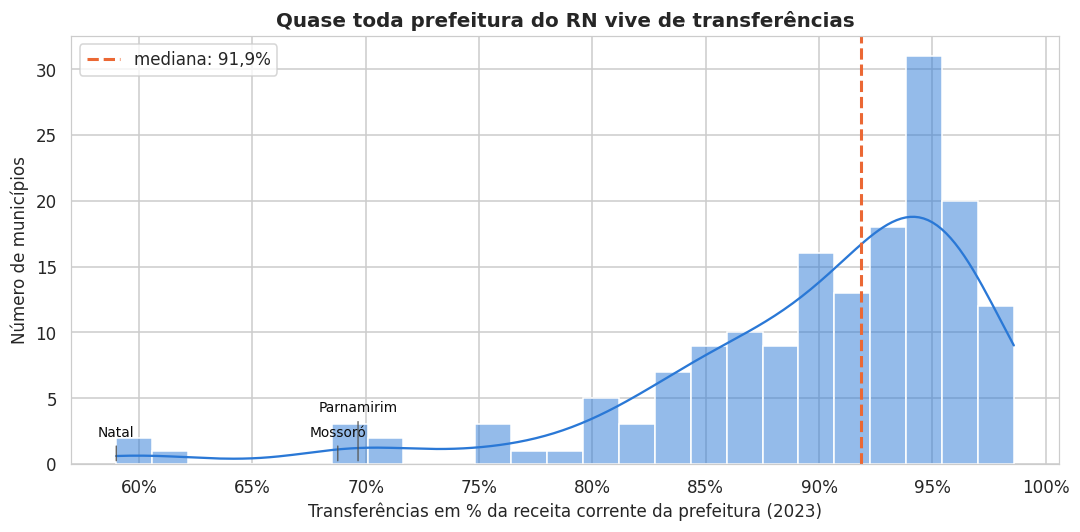

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(o['pct_transferencias'], bins=25, kde=True, color=AZUL, edgecolor='white', ax=ax)
med = o['pct_transferencias'].median()
ax.axvline(med, color=LARANJA, linestyle='--', linewidth=2, label=f'mediana: {virgula(med)}%')
for nome, altura in [('Natal', 18), ('Mossoró', 18), ('Parnamirim', 34)]:
    v = o.loc[o['municipio'] == nome, 'pct_transferencias'].iloc[0]
    ax.annotate(nome, (v, 0), xytext=(0, altura), textcoords='offset points', ha='center', fontsize=9, color=TEXTO,
                arrowprops={'arrowstyle': '-', 'color': TEXTO_2, 'lw': 0.8})
ax.xaxis.set_major_formatter(mticker.PercentFormatter(100, decimals=0))
ax.set_xlabel('Transferências em % da receita corrente da prefeitura (2023)')
ax.set_ylabel('Número de municípios')
ax.set_title('Quase toda prefeitura do RN vive de transferências')
ax.legend()
plt.tight_layout()
plt.savefig('graficos/05_dependencia_transferencias.png', bbox_inches='tight')
plt.show()

**Leitura:**
- Na prefeitura típica do RN, cerca de **92% da receita corrente vem de transferências** e só cerca de **4% de
  impostos próprios**. Só as cidades maiores (Natal, Mossoró, Parnamirim) têm arrecadação própria relevante.
- A maior transferência é o **FPM** (federal). Os 4 repasses estaduais deste estudo são cerca de **10%** da receita
  da prefeitura típica, mas passam de **40%** nas cidades com usinas.
- **Resposta à pergunta inicial:** a dependência é muito alta, mas os repasses **estaduais** pesam pouco para a
  maioria. Onde pesam muito é justamente nos municípios com indústria.

### 7.2 Cidades com usinas × cidades parecidas: quanto entra e onde é gasto

In [21]:
oi = o.set_index('municipio')
COLS_GASTO = ['Educação (R$/hab)', 'Saúde (R$/hab)', 'Administração (R$/hab)', 'Urbanismo (R$/hab)',
              'Legislativo (Câmara) (R$/hab)', 'Assistência social (R$/hab)']
COLS_ORC = ['rep_per_capita', 'pct_repasse_estadual', 'receita_pc', 'Total (R$/hab)'] + COLS_GASTO + ['saldo_fundeb_pc']
gemeos = list(dict.fromkeys(PARES['gemeo']))
resumo = pd.concat({
    'Com usinas (7)': oi.loc[OUTLIERS, COLS_ORC].median(),
    f'Parecidas, sem usina ({len(gemeos)})': oi.loc[gemeos, COLS_ORC].median(),
    'Demais municípios': oi.drop(OUTLIERS)[COLS_ORC].median(),
}, axis=1)
resumo['com usinas ÷ parecidas'] = resumo.iloc[:, 0] / resumo.iloc[:, 1]
resumo

,Com usinas (7),"Parecidas, sem usina (6)",Demais municípios,com usinas ÷ parecidas
rep_per_capita,"5,572.2",568.3,594.3,9.8
pct_repasse_estadual,41.1,9.1,9.7,4.5
receita_pc,"15,701.1","7,001.1","5,742.6",2.2
Total (R$/hab),"13,614.3","6,484.3","5,407.9",2.1
Educação (R$/hab),"3,343.1","1,890.1","1,692.9",1.8
Saúde (R$/hab),"3,103.4","1,929.6","1,480.9",1.6
Administração (R$/hab),"2,225.5",626.9,618.2,3.6
Urbanismo (R$/hab),988.8,866.7,499.9,1.1
Legislativo (Câmara) (R$/hab),727.2,247.6,202.9,2.9
Assistência social (R$/hab),674.5,554.1,182.4,1.2


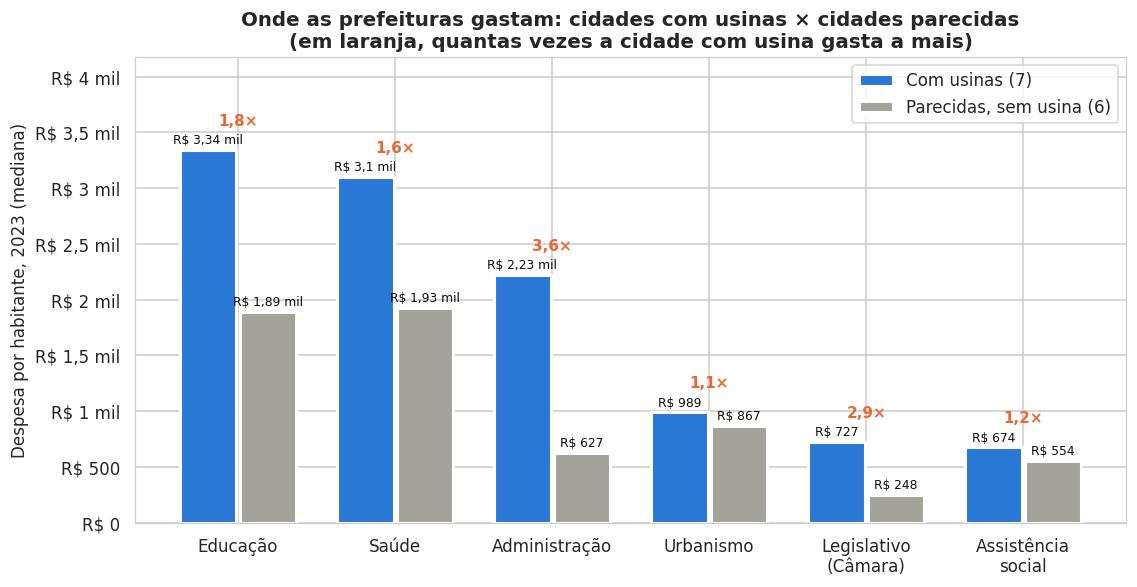

In [22]:
dados_graf = resumo.loc[COLS_GASTO, ['Com usinas (7)', f'Parecidas, sem usina ({len(gemeos)})']]
dados_graf.index = [c.replace(' (R$/hab)', '').replace(' (', '\n(').replace('ia s', 'ia\ns') for c in dados_graf.index]
fig, ax = plt.subplots(figsize=(10.5, 5.5))
x = np.arange(len(dados_graf))
for k, (grupo, cor) in enumerate(zip(dados_graf.columns, [AZUL, CINZA])):
    barras = ax.bar(x + (k - 0.5) * 0.38, dados_graf[grupo], width=0.36, color=cor, label=grupo,
                    edgecolor='white', linewidth=2)
    ax.bar_label(barras, labels=[reais(v) for v in dados_graf[grupo]], fontsize=8, padding=2, color=TEXTO)
for i, (a, b) in enumerate(zip(dados_graf.iloc[:, 0], dados_graf.iloc[:, 1])):
    ax.annotate(f'{virgula(a / b)}×', (i, max(a, b)), xytext=(0, 16), textcoords='offset points', ha='center',
                fontsize=10, fontweight='bold', color=LARANJA)
ax.set_xticks(x, dados_graf.index)
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_ylim(0, dados_graf.values.max() * 1.25)
ax.set_ylabel('Despesa por habitante, 2023 (mediana)')
ax.set_title('Onde as prefeituras gastam: cidades com usinas × cidades parecidas\n(em laranja, quantas vezes a cidade com usina gasta a mais)')
ax.legend()
plt.tight_layout()
plt.savefig('graficos/06_gasto_por_funcao_pares.png', bbox_inches='tight')
plt.show()

### 7.3 Como o dinheiro a mais é dividido
Para cada par, calculamos quanto a cidade com usina gasta **a mais por habitante** em cada área e somamos os 7 pares.

In [23]:
extra = pd.DataFrame({p['outlier']: oi.loc[p['outlier'], ['Total (R$/hab)'] + COLS_GASTO]
                      - oi.loc[p['gemeo'], ['Total (R$/hab)'] + COLS_GASTO] for _, p in PARES.iterrows()}).T.astype(float)
extra['Outras áreas (R$/hab)'] = extra['Total (R$/hab)'] - extra[COLS_GASTO].sum(axis=1)
divisao = (extra.drop(columns='Total (R$/hab)').sum() / extra['Total (R$/hab)'].sum() * 100)
divisao.index = [c.replace(' (R$/hab)', '') for c in divisao.index]
divisao = divisao.sort_values(ascending=False)
print('Gasto a mais por habitante (cidade com usina − cidade parecida), R$:')
display(extra.round(0))
divisao.round(1).to_frame('% do gasto a mais')

Gasto a mais por habitante (cidade com usina − cidade parecida), R$:


,Total (R$/hab),Educação (R$/hab),Saúde (R$/hab),Administração (R$/hab),Urbanismo (R$/hab),Legislativo (Câmara) (R$/hab),Assistência social (R$/hab),Outras áreas (R$/hab)
Guamaré,"13,866.0","3,114.0","4,023.0","1,435.0","1,559.0",973.0,"1,287.0","1,476.0"
São Bento do Norte,"5,262.0","1,006.0","1,076.0",953.0,"1,286.0",245.0,-45.0,741.0
Pedra Grande,"4,571.0",826.0,"1,147.0","2,070.0",-225.0,426.0,120.0,206.0
Parazinho,"4,676.0","1,311.0",405.0,"2,041.0",-119.0,326.0,546.0,165.0
Galinhos,"10,330.0","2,156.0","2,838.0","6,173.0","-1,042.0",387.0,-165.0,-17.0
Bodó,"3,769.0","1,559.0",277.0,327.0,-191.0,289.0,135.0,"1,373.0"
Serra do Mel,"3,264.0","1,691.0",65.0,944.0,142.0,228.0,-800.0,994.0


,% do gasto a mais
Administração,30.5
Educação,25.5
Saúde,21.5
Outras áreas,10.8
Legislativo (Câmara),6.3
Urbanismo,3.1
Assistência social,2.4


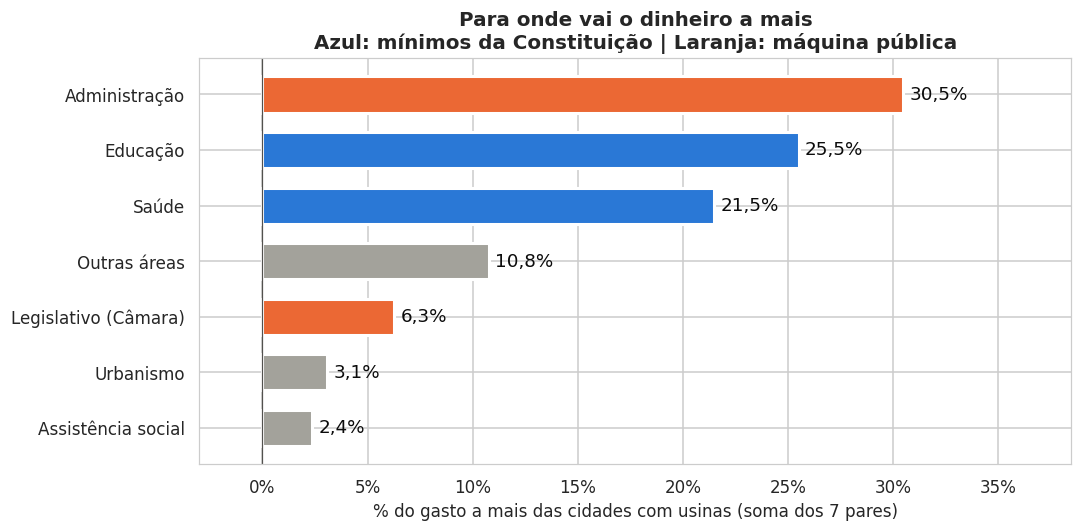

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
cores = [AZUL if nome in ['Educação', 'Saúde'] else (LARANJA if nome in ['Administração', 'Legislativo (Câmara)'] else CINZA)
         for nome in divisao.index]
barras = ax.barh(divisao.index, divisao.values, color=cores, edgecolor='white', linewidth=2, height=0.65)
ax.bar_label(barras, labels=[virgula(v) + '%' for v in divisao.values], padding=4, color=TEXTO)
ax.axvline(0, color=TEXTO_2, linewidth=0.8)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(100, decimals=0))
ax.set_xlim(min(0, divisao.min()) - 3, divisao.max() + 8)
ax.set_xlabel('% do gasto a mais das cidades com usinas (soma dos 7 pares)')
ax.set_title('Para onde vai o dinheiro a mais\nAzul: mínimos da Constituição | Laranja: máquina pública')
plt.tight_layout()
plt.savefig('graficos/07_divisao_do_gasto_extra.png', bbox_inches='tight')
plt.show()

**Leitura:**
- As cidades com usinas têm cerca do **dobro de receita por habitante** que as parecidas (R$ 15,7 mil contra R$ 7 mil) e gastam
  mais em quase tudo.
- **Administração** (prefeitura, pessoal, sede) é a área que mais leva o dinheiro a mais: cerca de **30%**. Somada à
  **Câmara de Vereadores** (cerca de 6%), a máquina pública fica com cerca de **37%**. O gasto da Câmara cresce
  sozinho, porque o limite dela é um percentual da receita (CF, art. 29-A).
- **Educação e saúde** levam juntas cerca de **47%**. Isso é esperado: a Constituição obriga a prefeitura a aplicar
  ao menos **25% em educação** (art. 212) e **15% em saúde** (LC 141/2012) do que arrecada com impostos e
  transferências, e o ICMS entra nessa conta.
- **Galinhos** é o caso extremo: gasta R$ 7,2 mil por habitante em administração, 7 vezes a cidade parecida.

**Cuidados:**
- Cada prefeitura classifica as despesas do seu jeito. "Administração" às vezes recebe gastos que outra prefeitura
  lançaria em urbanismo, por exemplo (Galinhos declara quase zero em urbanismo). Por isso olhamos a soma dos pares e
  não um município isolado.
- Gastar mais não quer dizer gastar mal nem bem: ver o resultado (educação, saúde) é o próximo passo.

### 7.4 O FUNDEB devolve uma parte para os outros municípios
20% do ICMS, do IPVA e do IPI que a prefeitura recebe fica retido no **FUNDEB** e volta para cada município de
acordo com o **número de alunos** na rede. Quem tem muito ICMS e poucos alunos **perde** nessa troca.

In [25]:
fundeb = oi.loc[OUTLIERS + gemeos, ['saldo_fundeb_pc']].assign(grupo=lambda t: np.where(t.index.isin(OUTLIERS), 'com usina', 'parecida'))
print('Prefeituras com saldo negativo no FUNDEB (perdem):', (o['saldo_fundeb_pc'] < 0).sum(), 'de', len(o))
print('Saldo total das 7 cidades com usinas:', reais((oi.loc[OUTLIERS, 'fundeb_recebido'] - oi.loc[OUTLIERS, 'fundeb_deduzido']).sum()))
fundeb.sort_values('saldo_fundeb_pc')

Prefeituras com saldo negativo no FUNDEB (perdem): 24 de 166
Saldo total das 7 cidades com usinas: R$ -19,24 mi


,saldo_fundeb_pc,grupo
municipio,,
Guamaré,-934.2,com usina
Galinhos,-766.1,com usina
São Bento do Norte,-619.5,com usina
Pedra Grande,-511.7,com usina
Santana do Seridó,-451.7,parecida
Parazinho,-448.7,com usina
Fernando Pedroza,-358.5,parecida
Bodó,-88.5,com usina
Angicos,170.0,parecida


**Leitura:**
- 6 das 7 cidades com usinas **perdem** no FUNDEB (Serra do Mel, que tem mais alunos, ganha). Juntos, deixam cerca de
  **R$ 19 milhões** em 2023 para os outros municípios.
- Duas cidades parecidas pequenas (Santana do Seridó e Fernando Pedroza) também perdem: no FUNDEB perde quem tem **poucos alunos
  em relação ao imposto que recebe**, não só quem tem indústria. Só 24 das 166 prefeituras perdem.
- É o único mecanismo do sistema que redistribui o ICMS por um critério social (número de alunos), e mesmo assim só
  sobre 20% do valor.

**Observação:** o valor recebido do FUNDEB também inclui a complementação da União, então o saldo é aproximado.

## 8. A população desses municípios vive melhor?
Se o dinheiro a mais chegasse à população, a renda dos moradores deveria ser maior que a das cidades parecidas.

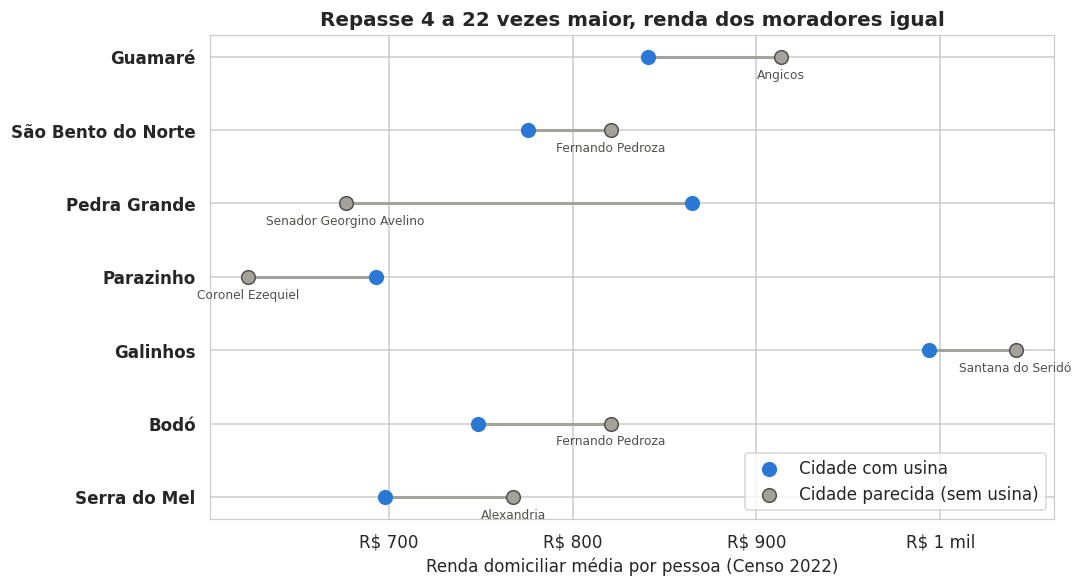

In [26]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, p in PARES.iterrows():
    a, b = info.loc[p['outlier'], 'renda_media_pc'], info.loc[p['gemeo'], 'renda_media_pc']
    ax.plot([a, b], [i, i], color=CINZA, linewidth=2, zorder=1)
    ax.scatter(a, i, color=AZUL, s=80, zorder=3, label='Cidade com usina' if i == 0 else None)
    ax.scatter(b, i, color=CINZA, s=80, zorder=3, edgecolor=TEXTO_2, label='Cidade parecida (sem usina)' if i == 0 else None)
    ax.annotate(p['gemeo'], (b, i), xytext=(0, -14), textcoords='offset points', ha='center', fontsize=8, color=TEXTO_2)
ax.set_yticks(range(len(PARES)), PARES['outlier'], fontweight='bold')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlabel('Renda domiciliar média por pessoa (Censo 2022)')
ax.set_title('Repasse 4 a 22 vezes maior, renda dos moradores igual')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('graficos/08_renda_pares.png', bbox_inches='tight')
plt.show()

In [27]:
print('Mediana da renda média por pessoa (Censo 2022):')
print('  com usinas:', reais(info.loc[OUTLIERS, 'renda_media_pc'].median()), '| parecidas:', reais(info.loc[gemeos, 'renda_media_pc'].median()))
print('  % com até ½ salário mínimo — com usinas:', virgula(info.loc[OUTLIERS, 'pct_ate_meio_sm_censo'].median()),
      '| parecidas:', virgula(info.loc[gemeos, 'pct_ate_meio_sm_censo'].median()))

Mediana da renda média por pessoa (Censo 2022):
  com usinas: R$ 776 | parecidas: R$ 794
  % com até ½ salário mínimo — com usinas: 55,5 | parecidas: 56,8


**Leitura:** a renda dos moradores das cidades com usinas é **igual à das parecidas**.

**Cuidado:** as cidades parecidas foram escolhidas por terem a **mesma pobreza** em 2022, e renda e pobreza andam juntas. Então
este gráfico, sozinho, não prova que o dinheiro não chegou à população. O teste certo compara **antes e depois** da
chegada das usinas, com cidades parecidas escolhidas pela situação de 2010: está no **notebook 07**.

## 9. Conclusões

**1. Por que o repasse não acompanha a pobreza: a regra.** 87% do repasse segue o índice do ICMS, e nenhum critério
desse índice mede pobreza. Em 2023, 75% do índice era o **valor adicionado** (atividade econômica), 15% uma **parte
igual** para todos, 5% população e 5% área. O resultado do CP2 era, portanto, o esperado pela lei.

**2. A parte igual explica por que os pequenos recebem mais por habitante.** Para o município típico, ela é a maior
fatia do repasse por habitante (cerca de RS 240 de RS 600).

**3. As cidades com usinas são explicadas pela indústria.** Comparando cidades parecidas (mesma população, mesma pobreza,
mesma região), a cidade com usina recebe de 4 a 22 vezes mais, e **quase toda a diferença vem do valor adicionado**, que
acompanha a indústria (energia eólica e petróleo/gás). A fatia salta no ano em que a atividade chega.

**4. Para onde vai o dinheiro: para a prefeitura, não para a renda das pessoas.**
- As cidades com usinas têm cerca do **dobro de receita por habitante** e gastam mais em tudo.
- Do gasto a mais, cerca de **47% vai para educação e saúde** (seguindo os mínimos da Constituição) e cerca de
  **37% para a máquina pública** (administração 30% e Câmara 6%).
- A **renda dos moradores é igual** à das parecidas (com a ressalva da seção 8; o teste de antes e depois está no
  notebook 07).
- Uma parte volta para os outros municípios pelo **FUNDEB** (cerca de R$ 19 mi em 2023).

**5. Dependência:** a prefeitura típica tira cerca de 92% da receita de transferências e só 4% de impostos próprios.
Os repasses estaduais pesam cerca de 10% na típica e mais de 40% nas cidades com usinas.

**Limitações:**
- A decomposição usa a população do Censo 2022 e a área do IBGE; a SET pode usar outra estimativa de população.
  O erro é pequeno (a parte da população é só 5%).
- O valor adicionado da lei não é igual ao do PIB do IBGE; usamos o do IBGE como aproximação.
- Os dados do SICONFI são declarados pelas prefeituras e a classificação por função varia entre elas.
- Porto do Mangue não entregou a DCA de 2023.

**Próximos passos:**
- Ver se o gasto a mais melhora **resultados**: IDEB (educação) e indicadores de saúde nos pares.
- Confirmar a hipótese da queda de Guamaré (venda dos campos terrestres da Petrobras).
- Repetir a decomposição para 2024 e 2025, quando entra o critério de **educação** (10%) e a parte igual cai para 10%.
- Juntar com convênios e emendas (colegas): esses recursos chegam mais aos municípios sem indústria?